In [1]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("arshkon/linkedin-job-postings")

print("Path to dataset files:", path)

Using Colab cache for faster access to the 'linkedin-job-postings' dataset.
Path to dataset files: /kaggle/input/linkedin-job-postings


In [2]:
import os

os.listdir(path)

['companies', 'mappings', 'jobs', 'postings.csv']

In [3]:
import pandas as pd

df = pd.read_csv(path + "/postings.csv")

In [4]:
df.head()

,job_id,company_name,title,description,max_salary,pay_period,location,company_id,views,med_salary,...,skills_desc,listed_time,posting_domain,sponsored,work_type,currency,compensation_type,normalized_salary,zip_code,fips
0,921716,Corcoran Sawyer Smith,Marketing Coordinator,Job descriptionA leading real estate firm in N...,20.0,HOURLY,"Princeton, NJ",2774458.0,20.0,NaN,...,Requirements: \n\nWe are seeking a College or ...,1.713398e+12,NaN,0,FULL_TIME,USD,BASE_SALARY,38480.0,8540.0,34021.0
1,1829192,NaN,Mental Health Therapist/Counselor,"At Aspen Therapy and Wellness , we are committ...",50.0,HOURLY,"Fort Collins, CO",NaN,1.0,NaN,...,NaN,1.712858e+12,NaN,0,FULL_TIME,USD,BASE_SALARY,83200.0,80521.0,8069.0
2,10998357,The National Exemplar,Assitant Restaurant Manager,The National Exemplar is accepting application...,65000.0,YEARLY,"Cincinnati, OH",64896719.0,8.0,NaN,...,We are currently accepting resumes for FOH - A...,1.713278e+12,NaN,0,FULL_TIME,USD,BASE_SALARY,55000.0,45202.0,39061.0
3,23221523,"Abrams Fensterman, LLP",Senior Elder Law / Trusts and Estates Associat...,Senior Associate Attorney - Elder Law / Trusts...,175000.0,YEARLY,"New Hyde Park, NY",766262.0,16.0,NaN,...,This position requires a baseline understandin...,1.712896e+12,NaN,0,FULL_TIME,USD,BASE_SALARY,157500.0,11040.0,36059.0
4,35982263,NaN,Service Technician,Looking for HVAC service tech with experience ...,80000.0,YEARLY,"Burlington, IA",NaN,3.0,NaN,...,NaN,1.713452e+12,NaN,0,FULL_TIME,USD,BASE_SALARY,70000.0,52601.0,19057.0


In [5]:
df.shape

(123849, 31)

In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 123849 entries, 0 to 123848
Data columns (total 31 columns):
 #   Column                      Non-Null Count   Dtype  
---  ------                      --------------   -----  
 0   job_id                      123849 non-null  int64  
 1   company_name                122130 non-null  object 
 2   title                       123849 non-null  object 
 3   description                 123842 non-null  object 
 4   max_salary                  29793 non-null   float64
 5   pay_period                  36073 non-null   object 
 6   location                    123849 non-null  object 
 7   company_id                  122132 non-null  float64
 8   views                       122160 non-null  float64
 9   med_salary                  6280 non-null    float64
 10  min_salary                  29793 non-null   float64
 11  formatted_work_type         123849 non-null  object 
 12  applies                     23320 non-null   float64
 13  original_liste

In [7]:
df.isna().sum()

,0
job_id,0
company_name,1719
title,0
description,7
max_salary,94056
pay_period,87776
location,0
company_id,1717
views,1689
med_salary,117569


In [8]:
(df.isna().sum() / len(df) * 100).round(2)

,0
job_id,0.00
company_name,1.39
title,0.00
description,0.01
max_salary,75.94
pay_period,70.87
location,0.00
company_id,1.39
views,1.36
med_salary,94.93


In [9]:
df["title"].value_counts().head(20)

,count
title,
Sales Manager,673
Customer Service Representative,373
Project Manager,354
Administrative Assistant,254
Senior Accountant,238
Executive Assistant,228
Salesperson,211
Registered Nurse,210
Receptionist,204


In [10]:
df["title"].str.contains("Data Analyst", case=False, na=False).sum()

np.int64(408)

In [11]:
df["title"].str.contains(
    "Data Scientist", case=False, na=False
).sum()

np.int64(247)

In [12]:
df.loc[
    df["title"].str.contains(
        "Data Analyst", case=False, na=False
    ),
    "title"
].value_counts().head(20)

,count
title,
Data Analyst,137
Senior Data Analyst,25
Online Data Analyst,20
Business Data Analyst,10
Junior Data Analyst,5
Financial Data Analyst,5
Master Data Analyst,5
Lead Data Analyst,4
Data Analyst-VA,3


In [13]:
df.loc[
    df["title"].str.contains(
        "Data Scientist", case=False, na=False
    ),
    "title"
].value_counts().head(20)

,count
title,
Data Scientist,56
Senior Data Scientist,21
Lead Data Scientist,11
Data Scientist Lead – Telematics (Remote),6
"Senior Data Scientist, Experimentation & Personalization",4
Data Scientist (Intermediate),4
"Senior Data Scientist, - AI Foundations, Personalization",4
Principal Data Scientist,4
Sr Data Scientist,3


In [14]:
# Finding job postings for Data Analyst positions
analyst_mask = df["title"].str.contains(
    "Data Analyst", case=False, na=False
)

# Finding job postings for Data Scientist positions
scientist_mask = df["title"].str.contains(
    "Data Scientist", case=False, na=False
)

# Combine both postings into one
job_mask = analyst_mask | scientist_mask

# Generating an independent DataFrame
jobs_df = df.loc[job_mask].copy()

In [15]:
jobs_df.shape

(654, 31)

In [16]:
jobs_df.head()

,job_id,company_name,title,description,max_salary,pay_period,location,company_id,views,med_salary,...,skills_desc,listed_time,posting_domain,sponsored,work_type,currency,compensation_type,normalized_salary,zip_code,fips
389,3813645405,Tenazx Inc,Data Analyst,Job Title: Data AnalystDuration: ContractLocat...,NaN,NaN,"Queens, NY",82537206.0,4.0,NaN,...,NaN,1.713465e+12,NaN,0,CONTRACT,NaN,NaN,NaN,11427.0,36081.0
670,3872787865,Radiant Systems Inc,eCommerce Data Analyst,Job Description: JOB SUMMARY:Responsible for c...,NaN,NaN,United States,3342169.0,102.0,NaN,...,NaN,1.713278e+12,NaN,0,CONTRACT,NaN,NaN,NaN,NaN,NaN
1044,3884432522,MCubeSoft,Wealth Management Business Data Analyst,Job Title: BUSINESS DATA ANALYST Location: Aus...,NaN,NaN,"Charlotte, NC",74604183.0,8.0,NaN,...,NaN,1.712346e+12,NaN,0,FULL_TIME,NaN,NaN,NaN,28202.0,37119.0
1277,3884434978,Outlier,"Senior Data Analyst - AI Training (Remote, Con...",Job Type: Contract\n\nWe don’t sponsor work vi...,NaN,HOURLY,United States,92583550.0,258.0,55.0,...,NaN,1.712350e+12,boards.greenhouse.io,0,CONTRACT,USD,BASE_SALARY,114400.0,NaN,NaN
1338,3884435309,Armstrong World Industries,Data Scientist Job,"Primary location: Remote, Remote\n\nRelocation...",NaN,NaN,United States,5968.0,164.0,NaN,...,NaN,1.712348e+12,jobs.armstrongceilings.com,0,FULL_TIME,NaN,NaN,NaN,NaN,NaN


In [17]:
jobs_df["job_id"].duplicated().sum()

np.int64(0)

In [18]:
jobs_df.isna().sum()

,0
job_id,0
company_name,3
title,0
description,0
max_salary,454
pay_period,436
location,0
company_id,3
views,8
med_salary,636


In [19]:
(jobs_df.isna().sum() / len(jobs_df) * 100).round(2)

,0
job_id,0.00
company_name,0.46
title,0.00
description,0.00
max_salary,69.42
pay_period,66.67
location,0.00
company_id,0.46
views,1.22
med_salary,97.25


In [20]:
# This will choose columns that target the two positions we are researching
columns = [
    "job_id",
    "title",
    "company_name",
    "description",
    "location",
    "normalized_salary",
    "min_salary",
    "max_salary",
    "pay_period",
    "currency",
    "formatted_experience_level",
    "work_type",
    "remote_allowed"
]

clean_df = jobs_df[columns].copy()

clean_df.head()

,job_id,title,company_name,description,location,normalized_salary,min_salary,max_salary,pay_period,currency,formatted_experience_level,work_type,remote_allowed
389,3813645405,Data Analyst,Tenazx Inc,Job Title: Data AnalystDuration: ContractLocat...,"Queens, NY",NaN,NaN,NaN,NaN,NaN,NaN,CONTRACT,NaN
670,3872787865,eCommerce Data Analyst,Radiant Systems Inc,Job Description: JOB SUMMARY:Responsible for c...,United States,NaN,NaN,NaN,NaN,NaN,NaN,CONTRACT,1.0
1044,3884432522,Wealth Management Business Data Analyst,MCubeSoft,Job Title: BUSINESS DATA ANALYST Location: Aus...,"Charlotte, NC",NaN,NaN,NaN,NaN,NaN,NaN,FULL_TIME,NaN
1277,3884434978,"Senior Data Analyst - AI Training (Remote, Con...",Outlier,Job Type: Contract\n\nWe don’t sponsor work vi...,United States,114400.0,NaN,NaN,HOURLY,USD,Mid-Senior level,CONTRACT,1.0
1338,3884435309,Data Scientist Job,Armstrong World Industries,"Primary location: Remote, Remote\n\nRelocation...",United States,NaN,NaN,NaN,NaN,NaN,Entry level,FULL_TIME,1.0


In [21]:
clean_df.shape

(654, 13)

In [22]:
clean_df.isna().sum()

,0
job_id,0
title,0
company_name,3
description,0
location,0
normalized_salary,436
min_salary,454
max_salary,454
pay_period,436
currency,436


In [23]:
# Generating a new column to categorize job roles
clean_df["job_category"] = "Data Analyst"

# Selecting Data Scientist roles
scientist_mask = clean_df["title"].str.contains(
    "Data Scientist", case=False, na=False
)

# Appointing these roles to the Data Scientist section
clean_df.loc[scientist_mask, "job_category"] = "Data Scientist"

# This will showcase the outcomes of the first ten rows
clean_df[["title", "job_category"]].head(10)


,title,job_category
389,Data Analyst,Data Analyst
670,eCommerce Data Analyst,Data Analyst
1044,Wealth Management Business Data Analyst,Data Analyst
1277,"Senior Data Analyst - AI Training (Remote, Con...",Data Analyst
1338,Data Scientist Job,Data Scientist
1755,Onsite Data Analyst || USC ONLY || FL LOCALS,Data Analyst
1814,Sr. Procurement Data Analyst,Data Analyst
2026,Design Data Analyst,Data Analyst
2098,Data Analyst - Expert with Excel,Data Analyst
2338,Legal Data Analyst (Dallas/Chicago),Data Analyst


In [24]:
clean_df["job_category"].value_counts()

,count
job_category,
Data Analyst,407
Data Scientist,247


In [25]:
clean_df.groupby("job_category")["job_id"].count()

,job_id
job_category,
Data Analyst,407
Data Scientist,247


In [26]:
# This will count the salaries available across different job categories
clean_df.groupby("job_category")["normalized_salary"].count()

,normalized_salary
job_category,
Data Analyst,129
Data Scientist,89


In [27]:
# This will showcase the statistics regarding salaries for both job categories
clean_df.groupby("job_category")["normalized_salary"].describe()

,count,mean,std,min,25%,50%,75%,max
job_category,,,,,,,,
Data Analyst,129.0,104765.743643,32083.162185,47840.0,83200.0,99840.0,125000.0,222650.0
Data Scientist,89.0,155477.746067,46775.726514,45.0,115000.0,162200.0,182000.0,252844.0


In [28]:
# This will show the different salary formats the dataset contains
clean_df["pay_period"].value_counts(dropna=False)

,count
pay_period,
NaN,436
YEARLY,146
HOURLY,72


In [29]:
# This will show the lowest normalized salaries, listing the first 10 rows
clean_df[["title", "normalized_salary", "min_salary", "max_salary", "pay_period",
         "currency"]
].sort_values("normalized_salary").head(10)

,title,normalized_salary,min_salary,max_salary,pay_period,currency
98450,Data Scientist Intern (Monetization Product an...,45.0,45.0,45.0,YEARLY,USD
62890,Data Analyst,47840.0,21.0,25.0,HOURLY,USD
76625,"Intern, Data Analyst (Projects) IOAO Supply Chain",52000.0,20.0,30.0,HOURLY,USD
9364,Data Analyst,55000.0,NaN,NaN,YEARLY,USD
41190,Data Analyst,55120.0,25.0,28.0,HOURLY,USD
41270,Data Analyst,56680.0,26.0,28.5,HOURLY,USD
38566,Data Analyst 1 - 10315,57200.0,25.0,30.0,HOURLY,USD
3024,Research Data Analyst 1 (75% FTE/Hybrid Opport...,60555.0,48360.0,72750.0,YEARLY,USD
73646,Research Data Analyst,61150.0,39000.0,83300.0,YEARLY,USD
64671,Data Analyst,61880.0,NaN,NaN,HOURLY,USD


In [30]:
# Will investigate salaries categorized by payment period
clean_df.groupby("pay_period")["normalized_salary"].describe()

,count,mean,std,min,25%,50%,75%,max
pay_period,,,,,,,,
HOURLY,72.0,113418.644444,39198.503262,47840.0,86840.0,109200.0,135200.0,223600.0
YEARLY,146.0,131412.040616,48068.178047,45.0,95000.0,122500.0,165337.5,252844.0


In [31]:
# Need to check whether the salary values utilized in the dataset are all in USD
clean_df["currency"].value_counts(dropna=False)

,count
currency,
NaN,436
USD,218


In [32]:
# Detecting any salaries that are too low (any potential errors in salary)
clean_df.loc[clean_df["normalized_salary"] < 30000,
             ["title", "normalized_salary", "min_salary",
              "max_salary", "pay_period", "currency"]]

,title,normalized_salary,min_salary,max_salary,pay_period,currency
98450,Data Scientist Intern (Monetization Product an...,45.0,45.0,45.0,YEARLY,USD


In [33]:
# Will sum up salaires that are less than $30,000
(clean_df["normalized_salary"] < 30000).sum()

np.int64(1)

In [34]:
# Will move forward with replacing the wrong salary with NaN since it states /
# $45/year, which is most likely incorrect and probably meant per hour, yet I /
# am not entirely sure so I will just with replace it with NaN instead

clean_df.loc[
    clean_df["normalized_salary"] == 45,
    "normalized_salary"
] = float("nan")

In [35]:
# Will examine any other salaries that appear misleading
(clean_df["normalized_salary"] < 30000).sum()

np.int64(0)

In [36]:
# Will now check salaries after removing the salary error and cleaning the data
clean_df.groupby("job_category")["normalized_salary"].describe()


,count,mean,std,min,25%,50%,75%,max
job_category,,,,,,,,
Data Analyst,129.0,104765.743643,32083.162185,47840.0,83200.000,99840.0,125000.0,222650.0
Data Scientist,88.0,157244.027273,43957.576140,74977.0,117488.875,162200.0,182750.0,252844.0


In [37]:
# Will look over the experience levels required by different companies
clean_df["formatted_experience_level"].value_counts(dropna=False)

,count
formatted_experience_level,
Mid-Senior level,234
NaN,187
Entry level,174
Associate,52
Director,3
Internship,3
Executive,1


In [38]:
# For any jobs with missing experience levels, I will replace this /
# with "Not Mentioned" from the dataset
clean_df["formatted_experience_level"] = clean_df[
    "formatted_experience_level"].fillna("Not Mentioned")

In [39]:
# Will now evualate levels after cleaning the data and replacing missing /
# experience levels
clean_df["formatted_experience_level"].value_counts(dropna=False)

,count
formatted_experience_level,
Mid-Senior level,234
Not Mentioned,187
Entry level,174
Associate,52
Director,3
Internship,3
Executive,1


In [40]:
# Will check the remote-work values, as well as any other values that are missing
clean_df["remote_allowed"].value_counts(dropna=False)

,count
remote_allowed,
NaN,429
1.0,225


In [41]:
# Creating a column that states whether a job offers any remote positions
clean_df["remote_availability"] = "Not Mentioned"

# Find jobs labeled as remote
clean_df.loc[clean_df["remote_allowed"] == 1, "remote_availability"
             ] = "Remote Option Offered"

# Find jobs labeled as not remote
clean_df.loc[clean_df["remote_allowed"] == 0, "remote_availability"
            ] = "Remote Option Not Offered"

In [42]:
# Need to look over remote-work categories after refining the dataset
clean_df["remote_availability"].value_counts(dropna=False)

,count
remote_availability,
Not Mentioned,429
Remote Option Offered,225


In [43]:
# This will idenitfy the first five descriptions from the dataset
clean_df["description"].head()

,description
389,Job Title: Data AnalystDuration: ContractLocat...
670,Job Description: JOB SUMMARY:Responsible for c...
1044,Job Title: BUSINESS DATA ANALYST Location: Aus...
1277,Job Type: Contract\n\nWe don’t sponsor work vi...
1338,"Primary location: Remote, Remote\n\nRelocation..."


In [44]:
# Will see if there are any job descriptions missing in the dataset
clean_df["description"].isna().sum()

np.int64(0)

In [45]:
# A new column will be constructed to include standardized descriptions
clean_df["description_clean"] = (clean_df["description"]
.str.lower()
.str.strip()
.str.replace(r"\s+", " ", regex=True)
)

# Will analyze the descriptions that were cleaned
clean_df[["description", "description_clean"]].head()

,description,description_clean
389,Job Title: Data AnalystDuration: ContractLocat...,job title: data analystduration: contractlocat...
670,Job Description: JOB SUMMARY:Responsible for c...,job description: job summary:responsible for c...
1044,Job Title: BUSINESS DATA ANALYST Location: Aus...,job title: business data analyst location: aus...
1277,Job Type: Contract\n\nWe don’t sponsor work vi...,job type: contract we don’t sponsor work visas...
1338,"Primary location: Remote, Remote\n\nRelocation...","primary location: remote, remote relocation of..."


In [46]:
# Code below will sum up all job descriptions containing python
clean_df["description_clean"].str.contains(
    r"\bpython\b", regex=True, na=False
).sum()

np.int64(350)

In [47]:
# The code below will compare any job categories that mention the keyword python
clean_df["python_mentioned"] = clean_df["description_clean"].str.contains(
    r"\bpython\b", regex=True, na=False
)

clean_df.groupby("job_category")["python_mentioned"].sum()

,python_mentioned
job_category,
Data Analyst,139
Data Scientist,211


In [48]:
# Code below will sum up all job descriptions containing sql
clean_df["description_clean"].str.contains(
    r"\bsql\b", regex=True, na=False
).sum()

np.int64(392)

In [49]:
# The code below will compare any job categories that mention the keyword sql
clean_df["sql_mentioned"] = clean_df["description_clean"].str.contains(
    r"\bsql\b", regex=True, na=False
)

clean_df.groupby("job_category")["sql_mentioned"].sum()

,sql_mentioned
job_category,
Data Analyst,245
Data Scientist,147


In [50]:
# Code below will sum up all job descriptions containing excel
clean_df["description_clean"].str.contains(
    r"\bexcel\b", regex=True, na=False
).sum()

np.int64(164)

In [51]:
# The code below will compare any job categories that mention the keyword excel
clean_df["excel_mentioned"] = clean_df["description_clean"].str.contains(
    r"\bexcel\b", regex=True, na=False
)

clean_df.groupby("job_category")["excel_mentioned"].sum()


,excel_mentioned
job_category,
Data Analyst,146
Data Scientist,18


In [52]:
# Code below will sum up all job descriptions containing R
clean_df["description_clean"].str.contains(
    r"\br\b", regex=True, na=False
).sum()

np.int64(201)

In [53]:
# The code below will compare any job categories that mention the keyword R
clean_df["r_mentioned"] = clean_df["description_clean"].str.contains(
    r"\br\b", regex=True, na=False
)

clean_df.groupby("job_category")["r_mentioned"].sum()

,r_mentioned
job_category,
Data Analyst,60
Data Scientist,141


In [54]:
# This will compute the percentage of jobs mentioning any of the skills we /
# listed above (python, sql, excel, r)

skills = ["python_mentioned", "sql_mentioned", "excel_mentioned", "r_mentioned"]

Percentage_of_Skills_across_jobs = (clean_df[skills].sum() / len(clean_df) * 100)

Percentage_of_Skills_across_jobs.round(2)


,0
python_mentioned,53.52
sql_mentioned,59.94
excel_mentioned,25.08
r_mentioned,30.73


In [55]:
# The code below will compare the skill percentages between different job types
Percentage_of_skills_across_job_category = (clean_df.groupby("job_category")[skills]
          .mean() * 100
).round(2)

Percentage_of_skills_across_job_category

,python_mentioned,sql_mentioned,excel_mentioned,r_mentioned
job_category,,,,
Data Analyst,34.15,60.20,35.87,14.74
Data Scientist,85.43,59.51,7.29,57.09


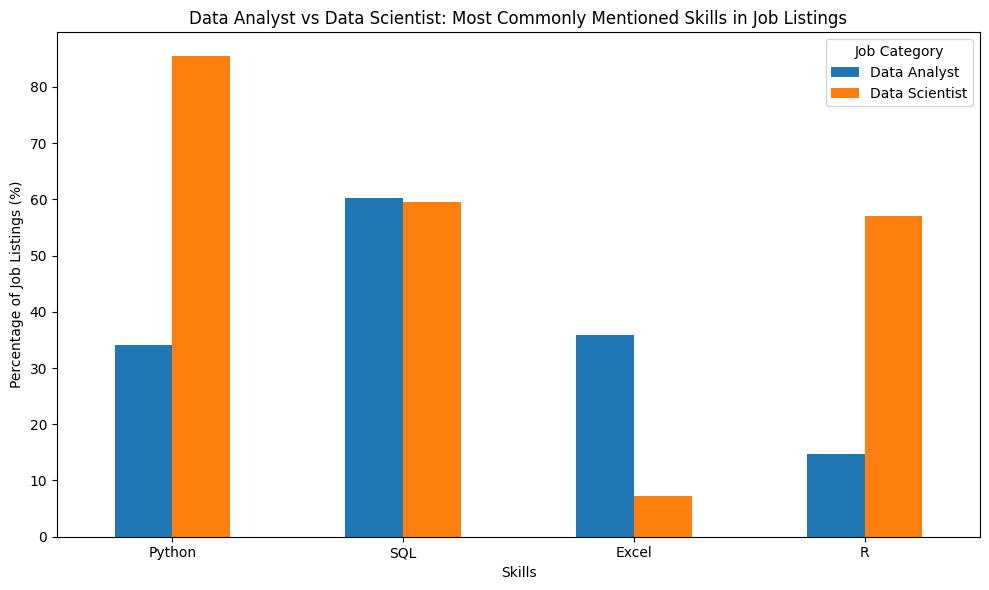

In [56]:
# Will now create a bar chart to compare the skills that are mentioned the most
# across data analyst and data scientist job listings
import matplotlib.pyplot as plt

Percentage_of_skills_across_job_category.T.plot(
    kind="bar",
    figsize=(10, 6)
)

plt.title("Data Analyst vs Data Scientist: Most Commonly Mentioned Skills in Job Listings")
plt.xlabel("Skills")
plt.ylabel("Percentage of Job Listings (%)")
plt.xticks(
  range(4),
  ["Python", "SQL", "Excel", "R"],
  rotation=0)
plt.legend(title="Job Category")
plt.tight_layout()
plt.show()


In [57]:
# The code below checks to see if there are any missing values in the dataset
clean_df.isna().sum()

,0
job_id,0
title,0
company_name,3
description,0
location,0
normalized_salary,437
min_salary,454
max_salary,454
pay_period,436
currency,436


In [58]:
# The code below will substitute company names that are missing with "Not Mentioned"
clean_df["company_name"] = clean_df["company_name"].fillna("Not Mentioned")

# After cleaning the data, the code below checks the company names to see /
# if any are still missing
clean_df["company_name"].isna().sum()

np.int64(0)

In [59]:
# Checking the data to make sure everthing is accurate
print("Dataset shape:", clean_df.shape)

# Checking the data to see if there are any duplicates for Job IDS
print("Duplicate job IDs:", clean_df["job_id"].duplicated().sum())

# The code below examines whether there are still any missing values after /
# cleaning the dataset
clean_df.isna().sum()

Dataset shape: (654, 20)
Duplicate job IDs: 0


,0
job_id,0
title,0
company_name,0
description,0
location,0
normalized_salary,437
min_salary,454
max_salary,454
pay_period,436
currency,436


In [60]:
# Exporting the cleaned dataset to give my teammates access to the cleane dataset
clean_df.to_csv("cleaned_dataset_jobs_STA141B_.csv", index=False)

In [61]:
from google.colab import files

files.download("cleaned_dataset_jobs_STA141B_.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>